<a href="https://colab.research.google.com/github/pskshyam/Langgraph-crash-course/blob/main/2-HumanAssistance/humanintheloop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Human In the Loop

In [1]:
! pip install -q langgraph langchain_groq langchain-tavily

In [4]:
from typing import Annotated

from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from langchain
from typing_extensions import TypedDict

from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

from langgraph.types import Command, interrupt

In [2]:
import os
from google.colab import userdata
os.environ["GROQ_API_KEY"] = userdata.get('GROQ_API_KEY')
os.environ["TAVILY_API_KEY"] = userdata.get('TAVILY_API_KEY')

### Define Model

In [3]:
from langchain.chat_models import init_chat_model
llm=init_chat_model("groq:qwen/qwen3.8-27b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.1', 'langchain': '1.4.7'}}, client=<groq.resources.chat.completions.Completions object at 0x7f92c518e510>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x7f92c518f230>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'))

### Define Tools

In [5]:
@tool
def human_assistance(query: str) -> str:
    """Request assistance from a human."""
    human_response = interrupt({"query": query})
    return human_response["data"]

tool = TavilySearch(max_results=2)
tools = [tool, human_assistance]

### Define Checkpointer

In [6]:
memory = MemorySaver()

# Create ReAct agent

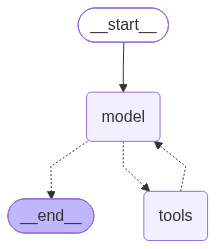

In [10]:
from langchain.agents import create_agent
graph = create_agent(llm, tools, checkpointer=memory)
graph

### Run Agent

In [11]:
user_input = "I need some expert guidance and assistance for building an AI agent. Could you request assistance for me?"
config = {"configurable": {"thread_id": "1"}}

events = graph.stream(
    {"messages": user_input},
    config,
    stream_mode="values",
)
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

I need some expert guidance and assistance for building an AI agent. Could you request assistance for me?
================================== Ai Message ==================================

I'll be glad to help with that. I'll reach out to a human agent to get expert guidance for you on building your AI agent.
Tool Calls:
  human_assistance (37bserrx6)
 Call ID: 37bserrx6
  Args:
    query: I need expert guidance and assistance for building an AI agent. Could you please connect me with someone who can help with this?
================================== Ai Message ==================================

I'll be glad to help with that. I'll reach out to a human agent to get expert guidance for you on building your AI agent.
Tool Calls:
  human_assistance (37bserrx6)
 Call ID: 37bserrx6
  Args:
    query: I need expert guidance and assistance for building an AI agent. Could you please connect me with someone who ca

In [12]:
human_response = (
    "We, the experts are here to help! We'd recommend you check out LangGraph to build your agent."
    " It's much more reliable and extensible than simple autonomous agents."
)

human_command = Command(resume={"data": human_response})

events = graph.stream(human_command, config, stream_mode="values")
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================== Ai Message ==================================

I'll be glad to help with that. I'll reach out to a human agent to get expert guidance for you on building your AI agent.
Tool Calls:
  human_assistance (37bserrx6)
 Call ID: 37bserrx6
  Args:
    query: I need expert guidance and assistance for building an AI agent. Could you please connect me with someone who can help with this?
================================= Tool Message =================================
Name: human_assistance

We, the experts are here to help! We'd recommend you check out LangGraph to build your agent. It's much more reliable and extensible than simple autonomous agents.
================================== Ai Message ==================================

Here's what the expert team recommended:

**They suggest using LangGraph** to build your AI agent. According to them, it's much more reliable and extensible than simple autonomous agents.

If you'd like, I can look up more details abo